[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch12-concepts_workbook.ipynb)

# Three answers to a headache question

Asked how to treat a headache, a pre-trained model gives the forum answer A
the lowest perplexity, 9.0, against 21.0 for B, a dose and a limit, and 24.0
for C, the same dose with an ulcer warning added. An assistant should rank C
first. Which signal teaches a model that order, and how does a model learn
from it? The lecture's numbers answer both: Bradley-Terry, the KL optimum,
the DPO loss and the agreement of two raters.

In [1]:
#@title Setup: run this cell first
import math

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# The running example, stylised as in the lecture: perplexity under the pre-trained model, the reward a reward model
# fitted to comparisons gives each answer, and the supervised model's probability of each answer.
PERPLEXITY = {"A": 9.0, "B": 21.0, "C": 24.0}
REWARD = {"A": -1.5, "B": 0.8, "C": 1.5}
REFERENCE = {"A": 0.2, "B": 0.4, "C": 0.4}
PAIRS = [("C", "B"), ("B", "A"), ("C", "A")]  # preferred answer first
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


def number(name, x, lo, hi):  # a number typed in a cell
    if type(x) not in (int, float) or not lo <= x <= hi:
        show = lambda v: f"{v:,}" if v == int(v) else f"{v:g}"  # noqa: E731
        raise Refused(f"{name} is {x!r}: {name} takes a number from {show(lo)} to {show(hi)}.")
    return x


def sigma(z):  # the logistic sigmoid, written so that a large |z| cannot overflow
    return 1 / (1 + math.exp(-z)) if z >= 0 else math.exp(z) / (1 + math.exp(z))


def minus_log_sigma(z):  # -ln sigma(z), the loss on a pair whose logit is z
    return math.log1p(math.exp(-z)) if z >= 0 else -z + math.log1p(math.exp(z))


def bars(title, labels, values, xlabel, focus=None, fmt="%.3f"):  # labelled bars, the focus bar in red
    fig, ax = plt.subplots(figsize=(6, 0.35 * len(values) + 1.3), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color=["C3" if x == focus else "C0" for x in labels])
    ax.bar_label(b, fmt=fmt, padding=2, fontsize=8)
    ax.set(title=title, xlabel=xlabel, xlim=(0, 1.2 * max(values)), ylim=(len(values) - 0.5, -0.5))
    plt.show()


# Step 1: Bradley-Terry. P(w over l) = sigma(r_w - r_l), and the reward model's loss on the pair is -ln of it.
def show_bradley_terry(shift):
    r = {a: REWARD[a] + number("SHIFT", shift, -1000, 1000) for a in REWARD}
    for w, l in PAIRS:
        print(f"{w} over {l}: rewards {r[w]:g} and {r[l]:g}, P = sigma({r[w] - r[l]:.1f}) = {sigma(r[w] - r[l]):.3f}, "
              f"loss {minus_log_sigma(r[w] - r[l]):.3f}")
    bars(f"preference probabilities, every reward plus {shift:g}", [f"{w} over {l}" for w, l in PAIRS],
         [sigma(r[w] - r[l]) for w, l in PAIRS], "probability that a reader prefers the first answer", focus="C over B")


# Step 2: the KL optimum pi*(a) = reference(a) e^(r(a) / beta) / Z, computed in logs so that a small beta cannot overflow.
def optimum(beta):
    logs = {a: math.log(REFERENCE[a]) + REWARD[a] / number("BETA", beta, 0.001, 10 ** 6) for a in REWARD}
    top = max(logs.values())
    weights = {a: math.exp(v - top) for a, v in logs.items()}
    return {a: w / sum(weights.values()) for a, w in weights.items()}


def show_optimum(beta):
    best = optimum(beta)
    print(f"beta {beta:g}: " + "; ".join(f"{a} from {REFERENCE[a]} to {best[a]:.4f}" for a in REWARD))
    fig, ax = plt.subplots(figsize=(6, 2.6), layout="constrained")
    ys = range(len(REWARD))
    ax.barh([y - 0.2 for y in ys], list(REFERENCE.values()), 0.4, color="0.6", label="supervised model, the reference")
    b = ax.barh([y + 0.2 for y in ys], list(best.values()), 0.4, color="C3", label=f"KL optimum at beta {beta:g}")
    ax.bar_label(b, fmt="%.4f", padding=2, fontsize=8)
    ax.set(title=f"the supervised model reweighted by e to the reward over {beta:g}", yticks=list(ys),
           yticklabels=list(REWARD), xlim=(0, 1.2), ylim=(2.6, -0.6), xlabel="probability of the answer")
    ax.legend(loc="upper right")
    plt.show()


# Step 3: the DPO loss of a pair, -ln sigma(beta (log-ratio of the preferred answer - log-ratio of the rejected one)).
def dpo(policy, reference, beta):
    for name, d in (("POLICY", policy), ("REFERENCE_LOG", reference)):
        if not isinstance(d, dict) or sorted(d) != ["B", "C"]:
            raise Refused(f"{name} is {d!r}: {name} takes the log-probabilities of C and B, as in {{'C': -40.0, 'B': -40.0}}.")
        [number(f"{name}['{a}']", d[a], -10000, 0) for a in d]
    ratio = {a: policy[a] - reference[a] for a in policy}
    margin = ratio["C"] - ratio["B"]
    return ratio, margin, minus_log_sigma(number("BETA_DPO", beta, 0.001, 100) * margin)


def show_dpo(policy, reference, beta):
    ratio, margin, loss = dpo(policy, reference, beta)
    print(f"log-ratios C {ratio['C']:+.1f} and B {ratio['B']:+.1f}, margin {margin:.1f}, z {beta * margin:.3g}, loss {loss:.3f}")
    ms = [m / 10 for m in range(-100, 101)]
    fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
    ax.plot(ms, [minus_log_sigma(beta * m) for m in ms], color="C0", label=f"DPO loss at beta {beta:g}")
    ax.axhline(math.log(2), color="0.5", ls="--", label="ln 2, the policy equal to the reference")
    ax.plot([margin], [loss], "o", color="C3", label=f"this pair, margin {margin:.1f}")
    ax.set(title="the DPO loss against the margin of log-ratios", xlabel="margin, log-ratio of C minus log-ratio of B",
           ylabel="loss")
    ax.legend()
    plt.show()


# Appendix: two raters agree when both are right or both are wrong, a = p^2 + (1 - p)^2, so p = (1 + sqrt(2a - 1)) / 2.
def accuracy(per_cent):
    return (1 + math.sqrt(2 * number("AGREEMENT", per_cent, 50, 100) / 100 - 1)) / 2


def show_agreement(per_cent):
    p = accuracy(per_cent)
    print(f"agreement {per_cent:g} per cent: each rater right {100 * p:.1f} per cent; of 1,000 pairs both right on "
          f"{1000 * p * p:.0f}, both wrong on {1000 * (1 - p) ** 2:.0f}")
    xs = [50 + j / 2 for j in range(101)]
    fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
    ax.plot(xs, [100 * accuracy(x) for x in xs], color="C0", label="accuracy each rater needs, errors independent")
    ax.plot([per_cent], [100 * p], "o", color="C3", label=f"agreement {per_cent:g} per cent")
    ax.set(title="agreement of two raters and the accuracy behind it", xlabel="agreement, per cent",
           ylabel="accuracy of each rater, per cent")
    ax.legend()
    plt.show()

## 1. Bradley-Terry: from rewards to a preference

A reward model gives each answer one number: C 1.5, B 0.8 and A -1.5.
Bradley and Terry turn the difference of two rewards into the probability
that a reader prefers the first answer, the sigmoid of the difference. The
reward model's loss on a pair is minus the log of that probability. Run the
cell. Then set `SHIFT` to 100, which adds 100 to every reward: which
probability or loss changes?

C over B: rewards 1.5 and 0.8, P = sigma(0.7) = 0.668, loss 0.403
B over A: rewards 0.8 and -1.5, P = sigma(2.3) = 0.909, loss 0.096
C over A: rewards 1.5 and -1.5, P = sigma(3.0) = 0.953, loss 0.049


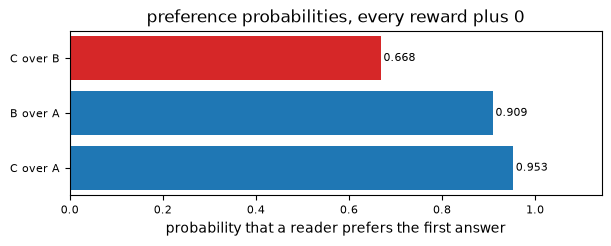

In [2]:
SHIFT = 0
show_bradley_terry(SHIFT)

### Solution

In [3]:
gap = REWARD["C"] - REWARD["B"]
display(Markdown(f"C beats B with probability {sigma(gap):.3f} at a loss of {minus_log_sigma(gap):.3f}, B beats A with "
                 f"{sigma(REWARD['B'] - REWARD['A']):.3f} and C beats A with {sigma(REWARD['C'] - REWARD['A']):.3f}. Adding "
                 f"{100} to every reward leaves each difference, and so each probability and loss, as it was: the rewards rank "
                 f"the answers C, B, A, the reverse of the order A, B, C that perplexities of {PERPLEXITY['A']}, {PERPLEXITY['B']} "
                 f"and {PERPLEXITY['C']} give."))

C beats B with probability 0.668 at a loss of 0.403, B beats A with 0.909 and C beats A with 0.953. Adding 100 to every reward leaves each difference, and so each probability and loss, as it was: the rewards rank the answers C, B, A, the reverse of the order A, B, C that perplexities of 9.0, 21.0 and 24.0 give.

## 2. The KL optimum

PPO raises the reward minus beta times the KL divergence from the supervised
model. The best policy for that objective multiplies the supervised model's
probabilities, 0.2 for A and 0.4 for B and C, by e to the power of the
reward over beta, and divides by their sum. Run the cell for `BETA` 1. Then
set `BETA` to 0.01 and to 100: where does the policy go at each end?

beta 1: A from 0.2 to 0.0164; B from 0.4 to 0.3264; C from 0.4 to 0.6573


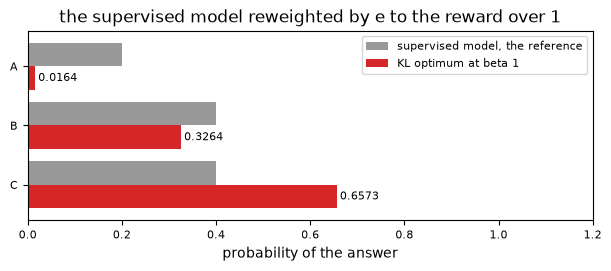

In [4]:
BETA = 1
show_optimum(BETA)

### Solution

In [5]:
one, small, large = optimum(1), optimum(0.01), optimum(100)
display(Markdown(f"At beta 1 the policy moves A from {REFERENCE['A']} to {one['A']:.4f} and C from {REFERENCE['C']} to "
                 f"{one['C']:.4f}. At beta 0.01 it puts {small['C']:.4f} on C, the answer with the highest reward; at beta "
                 f"{100} it puts {large['A']:.3f}, {large['B']:.3f} and {large['C']:.3f} on A, B and C, close to the supervised "
                 f"model: a large beta holds the policy at the reference."))

At beta 1 the policy moves A from 0.2 to 0.0164 and C from 0.4 to 0.6573. At beta 0.01 it puts 1.0000 on C, the answer with the highest reward; at beta 100 it puts 0.196, 0.401 and 0.404 on A, B and C, close to the supervised model: a large beta holds the policy at the reference.

## 3. The DPO loss

DPO needs four log-probabilities: of the preferred answer C and the rejected
answer B, under the policy being trained and under the reference. An
answer's log-ratio is its policy log-probability minus its reference
log-probability. The loss is minus the log of the sigmoid of beta times the
difference of the two log-ratios. Run the cell for the lecture's pair. Then
set the policy's log-probabilities to -38.0 for C and -43.0 for B: what is
the loss now?

log-ratios C +1.0 and B -1.5, margin 2.5, z 0.25, loss 0.576


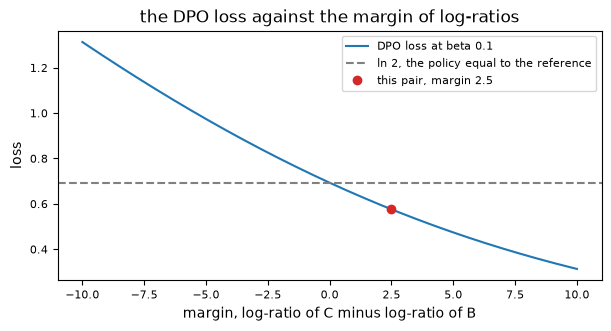

In [6]:
POLICY = {"C": -39.0, "B": -41.5}
REFERENCE_LOG = {"C": -40.0, "B": -40.0}
BETA_DPO = 0.1
show_dpo(POLICY, REFERENCE_LOG, BETA_DPO)

### Solution

In [7]:
(r1, m1, l1), (r2, m2, l2) = dpo(POLICY, REFERENCE_LOG, 0.1), dpo({"C": -38.0, "B": -43.0}, REFERENCE_LOG, 0.1)
display(Markdown(f"The log-ratios are {r1['C']:+.1f} and {r1['B']:+.1f}, the margin {m1:.1f} and the loss {l1:.3f}, below ln 2 "
                 f"= {math.log(2):.3f}, the loss while the policy equals the reference. At -38.0 and -43.0 the log-ratios are "
                 f"{r2['C']:+.1f} and {r2['B']:+.1f}, the margin {m2:.1f} and the loss {l2:.3f}. No reward model enters."))

The log-ratios are +1.0 and -1.5, the margin 2.5 and the loss 0.576, below ln 2 = 0.693, the loss while the policy equals the reference. At -38.0 and -43.0 the log-ratios are +2.0 and -3.0, the margin 5.0 and the loss 0.474. No reward model enters.

## Appendix. Agreement and accuracy

Two raters pick the better of two answers. They agree when both are right
or both are wrong, so two raters each right with probability p, errors
independent, agree on p squared plus (1 - p) squared of the pairs. The cell
turns an agreement of 80 per cent back into each rater's accuracy.

agreement 80 per cent: each rater right 88.7 per cent; of 1,000 pairs both right on 787, both wrong on 13


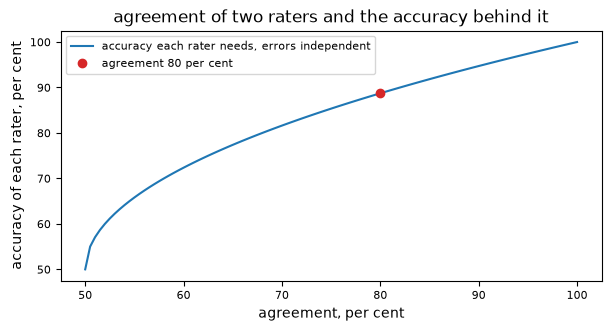

In [8]:
show_agreement(80)

**Exercise.** Set `AGREEMENT` to 70: what accuracy does each rater have?
Then set it to 50, the agreement of two raters who toss coins.

agreement 80 per cent: each rater right 88.7 per cent; of 1,000 pairs both right on 787, both wrong on 13


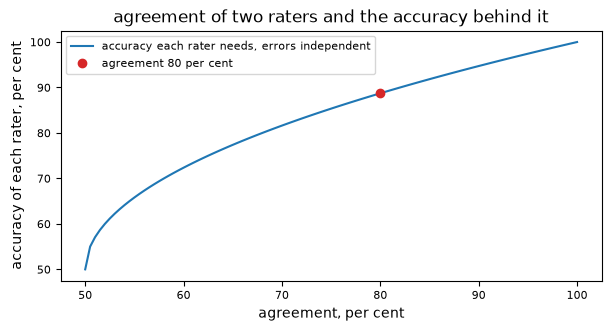

In [9]:
AGREEMENT = 80
show_agreement(AGREEMENT)

### Solution

In [10]:
display(Markdown(f"Agreement of {80} per cent implies {100 * accuracy(80):.1f} per cent for each rater, {70} per cent implies "
                 f"{100 * accuracy(70):.1f}, and {50} per cent implies {100 * accuracy(50):.0f}, a coin. Agreement says how often "
                 f"two raters match; read as accuracy, it assumes that their errors are independent."))

Agreement of 80 per cent implies 88.7 per cent for each rater, 70 per cent implies 81.6, and 50 per cent implies 50, a coin. Agreement says how often two raters match; read as accuracy, it assumes that their errors are independent.